In [1]:
import os
import glob
import json
import pandas as pd
import re
from typing import Optional, Tuple, Iterable, List
import matplotlib.pyplot as plt
import PIL.Image as Image

In [6]:
HOLDOUT_SET_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/labels/holdout"

In [7]:
glob_pattern = os.path.join(HOLDOUT_SET_DIR, "*.txt")
labels_paths = glob.glob(glob_pattern)
labels_names = [os.path.basename(p) for p in labels_paths]
len(labels_names)

148

In [8]:
# Read YOLO labels from all files in labels_paths
# Each line: class_id x_center y_center width height (normalized)
labels = []
for label_path in labels_paths:
    with open(label_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            if len(parts) < 5:
                continue
            class_id = int(parts[0])
            x_center, y_center, width, height = map(float, parts[1:5])
            labels.append({
                'label_path': label_path,
                'class_id': class_id,
                'x_center': x_center,
                'y_center': y_center,
                'width': width,
                'height': height,
            })

labels[:5]


[{'label_path': '/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/labels/holdout/4.2_batch1____4.2_H_cam_260_MenivimDesk_141.txt',
  'class_id': 0,
  'x_center': 0.5674531250000001,
  'y_center': 0.8278125000000001,
  'width': 0.16134375,
  'height': 0.344375},
 {'label_path': '/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/labels/holdout/4.2_batch2____4.2_H_cam_302_spacesMR_55.txt',
  'class_id': 0,
  'x_center': 0.8442812500000001,
  'y_center': 0.5602083333333333,
  'width': 0.14156249999999992,
  'height': 0.11458333333333326},
 {'label_path': '/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/labels/holdout/4.2_batch2____4.2_H_cam_302_spacesMR_55.txt',
  'class_id': 0,
  'x_center': 0.7215625,
  'y_center': 0.29194791666666664,
  'width': 0.14406249999999998,
  'height': 0.18347916666666664},
 {'label_path': '/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/labels/holdout/4.2_batch2____4.2_H_c

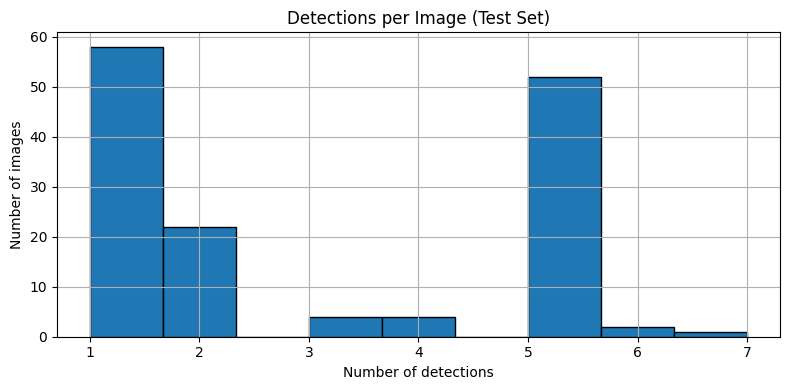

In [10]:
import matplotlib.pyplot as plt
from collections import Counter

# Count detections per image based on label_path
counts_by_image = Counter([item['label_path'] for item in labels])
detections_per_image = list(counts_by_image.values())

plt.figure(figsize=(8, 4))
plt.hist(detections_per_image, bins=9, edgecolor='black')
plt.title('Detections per Image (Test Set)')
plt.xlabel('Number of detections')
plt.ylabel('Number of images')
plt.tight_layout()
plt.grid()
plt.show()


In [ ]:
import os
import glob
import json
import pandas as pd
import re
from typing import Optional, Tuple, Iterable, List
import matplotlib.pyplot as plt
import PIL.Image as Image

In [ ]:
HOLDOUT_SET_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/images/holdout"
TRAIN_SET_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/images/train"
VAL_SET_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/images/val"

In [ ]:
glob_pattern = os.path.join(HOLDOUT_SET_DIR, "*.jpg")
image_paths = glob.glob(glob_pattern)
img_names = [os.path.basename(p) for p in image_paths]
len(img_names)

148

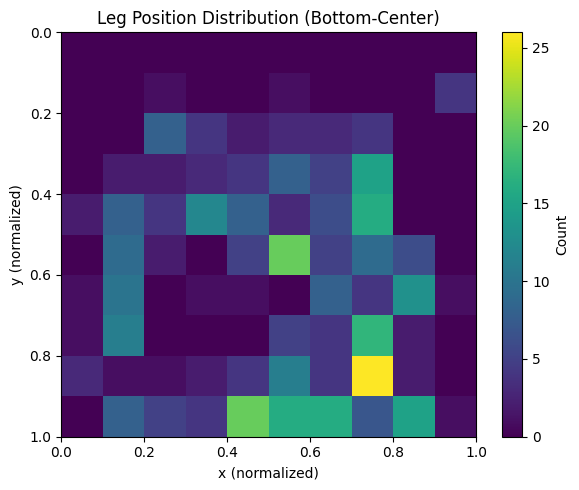

In [14]:
# 2D histogram of leg positions across the frame
# Approximate leg position as bottom-center of the bbox
x_legs = [item['x_center'] for item in labels]
y_legs = [item['y_center'] + 0.5 * item['height'] for item in labels]

plt.figure(figsize=(6, 5))
plt.hist2d(x_legs, y_legs, bins=10, range=[[0, 1], [0, 1]])#, cmap='magma')
plt.colorbar(label='Count')
plt.title('Leg Position Distribution (Bottom-Center)')
plt.xlabel('x (normalized)')
plt.ylabel('y (normalized)')
plt.ylim(1, 0)
plt.tight_layout()
plt.show()
